# Домашнее задание: архитектура систем текстовой классификации

Добро пожаловать на бизнес-кейс по текстовой классификации!

В рамках данного домашнего задания вам предстоит пройти по всем этапам решения кейса, которые обычно затрагиваются при решении реальных продуктовых задач, а также кейсов на секциях по ML System Design.

Часть заданий требует текстового ответа в свободной форме, часть заданий - написания кода, обучения и инференса моделей и тп. В большинстве разделов нет сугубо правильных ответов или единственно верной реализации, однако есть хорошие практики и возможность выбрать из нескольких вариантов оптимальный. Поэтому в рамках задания местами надо будет делать выбор, от которого будет зависеть качество вашего потенциального продакшн-решения, возможности его поддержки и масштабирования.

Детали реализации вы можете выбирать любые, которые вам больше нравятся или кажется более удобными, в том числе по принципу "работает быстрее аналогов без существенной потери в качестве". Однако важное требование - **соблюдать структуру разделов в данном ноутбуке** -- это поможет решить задачу правильно, а также упростить проверку и написание фидбека по решению.

Представьте, что к вам пришел бизнес и попросил сделать супер-крутую систему по категоризации новостей. Как обычно бывает, единственное, что у вас есть - это формулировка задачи от продакт-менеджера; всё остальное он ожидает от вас.

Приятного кодинга!

## 1. Формулировка бизнес-задачи

**Контекст (от лица бизнеса):**  
Мы хотим автоматически распределять публикации нашего новостного портала по трем главным темам — политика, экономика, культура — чтобы:

- Улучшить таргетинг рекламных блоков.  
- Персонализировать ленту для пользователей.  
- Снизить ручные затраты редакторов.

**Чёткое описание задачи:**
> «Для каждой новости (заголовок + текст) автоматически определить, относится ли она к разделам `политика`, `экономика`, `культура`. Возможна множественная классификация (одна новость может быть сразу в нескольких разделах).»


## 2. Бизнес-метрики - 1 балл

Предложите бизнес-метрики, которые может хотеть оптимизировать бизнес в соответствии с формулировкой задачи. Предложите хотя три метрики, и постарайтесь их оцифровать, чтобы результаты были измеримы (насколько процентов что-то должно увеличиться?). Воспринимайте это как "прицелочные" цифры, к которым можно реалистично стремиться (реальные цифры на старте часто непонятно, но измеримые цели помогают четче формировать ожидания и текущее положение относительно них; в дальнейшем эти цифры можно корректировать на реальность).

In [1]:
# ваш ответ тут
# ---- Ваш код здесь ----
print("""
      CTR по рекламе
      Количество переходов по рубрикам
      Трудозатраты редакторов
      Количество прочтений статей (время удержания)
""")
# ---- Конец кода ----


      Количество переходов по рубрикам
      Трудозатраты редакторов
      Количество прочтений статей (время удержания)



## 3. Сведение к ML-задаче - 2 балла

Сведите бизнес-задачу к задаче машинного обучения, опишите входные данные и метки:

- **Тип задачи**:
- **Объект**:
- **Метки**:


In [ ]:
# ваш ответ тут
# ---- Ваш код здесь ----
print("""
- **Тип задачи**:
      multilabel Классификация
- **Объект**:
      Публикации на новостном портале
- **Метки**:
      политика, экономика, культура
""")
# ---- Конец кода ----

## 4. ML-метрики - 2 балла

Сформулируйте какие метрики вашей модели машинного обучения вы будете отслеживать в соответствии с ML-задачей, к которой вы свели бизнес-задачу. Укажите оффлайн метрики и предложите онлайн-метрики, которые вы в теории могли бы замерять в рамках A/B и в проде.

In [ ]:
# ваш ответ тут
# ---- Ваш код здесь ----
print("""
- Оффлайн
  - F1
- Онлайн
  - время прочтения статей (время удержания внимания пользователя)
  - Количество лайков?
  - количество редакторских правок
""")
# ---- Конец кода ----

## 5. Данные и разметка - 8 баллов

В данном пункте нам будет необходимо сделать магию -- за 0 рублей и две чашки кофе получить неплохую разметку, на которой можно будет обучаться.

Тк у вашего новостного агенства пока еще нет ни новостей, ни логов для них, ваши коллеги уже собрали по разным новостным сайтам логи с заголовком и текстом новости (а также источником и датой на всякий) в файле crawled_data.tsv. Необходимо считать и обработать данные из этого файла, в идеале с помощью pandas DataFrame.

Как мы обсуждали на лекции, по-хорошему, работа с данными должна идти немного в другой последовательности, нежели будем делать мы: обычно сначала мы собираемся с бизнесом, пишем и оттачиваем инструкцию и собираем golden dataset. В рамках данной задачи будем считать, что у нас такой возможности нет, и нам будет ок получить MVP-разметку с помощью LLM -- это быстро, задача не самая сложная для LLM, плюс в целом качество такой разметки можно контролировать и улучшать при необходимости.

В этом пункте необходимо выбрать какую-нибудь open-source LLM, написать к ней промпт (можно простой и небольшой) и разметить какое-то количество данных, которое вам может показаться достаточным для обучения в этой задаче. Можете начать с небольшого количества, и постепенно его увеличивать, отслеживая, как при этом меняется качество.

LLM для разметки можно выбирать любую, но вам предстоит соблюсти баланс между качеством и возможостью инферить ее на GPU. В качестве неплохой модели для разметки русскоязычных текстов можете использовать https://huggingface.co/IlyaGusev/saiga_yandexgpt_8b: ее несложно проинферить кодом и она уже оптимизирована и влезает в GPU T4 на колабе. Можно выбирать и любую другую модель, но, возможно, вам придется повозиться с ее инференсом.

Далее вам необходимо будет реализовать функцию для инференса этой LLM с учетом промпта и входа, и циклом получить разметку по всем трем категориям из задачи. Будьте максимально аккуратны с используемой памятью, иначе в середине цикла инференс может падать с ошибкой Cuda Out of Memory. Для избежания этого можете после каждого инференса делать следующее:
- torch.cuda.empty_cache()
- перетаскивать **всё** вычисленное с GPU на CPU
- удалять все уже использованное переменные через del
- ограничивать размер входа и выхода
- если падают единичные примеры -- выкидывать их

В конечном счете в вашем датафрейме должны оказаться следующие колонки:

`['source', 'title', 'text', 'publication_date', 'politics', 'economy',
       'culture', 'generation']`,
где `generation` -- ответ генеративной модели в сыром виде; 'politics', 'economy', 'culture' -- наличие категории со значением 1/0, полученные из generation.

Отлаживайте разметку на небольшом семпле данных. Как только разметите нужное вам количество примеров, не забудьте сохранить их в отдельный файл, чтобы не потерять разметку.

Для искушенных - можно пользоваться vLLM для ускорения инференса или together https://api.together.xyz/signin?redirectUrl=%2F (они дают один доллар бесплатно)

In [1]:
import pandas as pd
df = pd.read_csv('crawleddata.tsv', sep="\t", )
columns = ['source', 'title', 'text', 'publication_date']
df.columns = columns
df = df[df['source'].notna() & df['title'].notna() & df['text'].notna() & df['publication_date'].notna()]
df 

,source,title,text,publication_date
0,lenta.ru,Загитова согласилась вести «Ледниковый период»,Олимпийская чемпионка по фигурному катанию Ал...,2020-08-31T20:04:00+03:00
1,lenta.ru,Объяснена опасность однообразного питания,Российский врач-диетолог Римма Мойсенко объясн...,2020-08-31T20:07:00+03:00
2,lenta.ru,«Предохраняться? А зачем?»,В 2019 году телеканал «Ю» запустил адаптацию з...,2020-08-30T00:04:00+03:00
3,lenta.ru,Ефремов систематически употреблял наркотики,Актер Михаил Ефремов систематически употребл...,2020-08-31T18:27:00+03:00
4,lenta.ru,"«Вы живете в мире, созданном блондинкой»",27 августа выходит новый роман Виктора Пелеви...,2020-08-27T00:02:00+03:00
...,...,...,...,...
21063,ria.ru,Самолеты НАТО стали чаще летать у границ Росси...,"МОСКВА, 23 дек - РИА Новости. Интенсивность п...",00:39 23.12.2019 (обновлено: 18:27 03.03.2020)
21064,ria.ru,Сюткин оценил шутку Шнурова над обидевшим Гага...,"МОСКВА, 23 дек — РИА Новости. Певец Валерий ...",00:50 23.12.2019 (обновлено: 18:27 03.03.2020)
21065,ria.ru,Владимир Путин откроет железнодорожное движени...,"МОСКВА, 23 дек — РИА Новости. Владимир Путин...",01:07 23.12.2019 (обновлено: 16:19 11.01.2020)
21066,ria.ru,Концертный директор прокомментировал скандал Б...,"МОСКВА, 23 дек — РИА Новости. Концертный дире...",01:49 23.12.2019 (обновлено: 18:27 03.03.2020)


In [2]:

from typing import List, Union, Literal, Annotated
from annotated_types import MaxLen, Le, MinLen
from pydantic import BaseModel, Field
import json
from openai import OpenAI
#ollama endpoint
class Labels(BaseModel):
    economy: bool = Field('Является новостью экономики')
    culture: bool = Field('Является новостью культуры')
    politics: bool = Field('Является новостью политики')
    other: bool = Field('ДРУГОЕ')
    generation: str = Field('ответ в сыром виде')
client = OpenAI(base_url='http://192.168.1.3:11434/v1', api_key='ollama', )
prompt = """
    Ты помошник редактора новостей который занимается категорированием новостей.
    Твоя задача соотнести каждую входящую статью с определенными рубриками:
    -экономика
    -культура
    -политика
    -другое
    рубрика культура обычно не пересекается с рубриками политики и экономики
"""


In [3]:
def process_row(source: str, title: str, text: str, publication_date: str):
    log = [
                    {"role": "system", "content": prompt},
                    {"role": "user", "content": title + ' ' +  text},
            ]
    completion = client.beta.chat.completions.parse(
                         model="OxW/Saiga_YandexGPT_8B:Q8_0",
                         response_format=Labels,
                         messages=log,
                         max_completion_tokens=1000,
                         #reasoning_effort='low',
                         temperature=0.15
                     )
    r =[]
    for c in completion.choices:
        data = json.loads(c.message.content)
        d = {
            'source':  source,
            'title': title, 
            'text': text,
            'publication_date': publication_date,
            'politics': data['politics'],
            'economy': data['economy'],
            'culture': data['culture'],
            'generation': c.message
        }
        r.append(d)
    
    return r
result = pd.DataFrame()
for idx, row in df[:5000].iterrows():
    #print(process_row(row['source'], row['title'], row['text'][:1500], row['publication_date']))
    df_new = pd.DataFrame(process_row(row['source'], row['title'], row['text'][:3000], row['publication_date']))
    result = pd.concat([result, df_new], ignore_index=True)
result.to_csv('prepared.csv', sep=';', index=False)
#в теории можно распараллелить

APIConnectionError: Connection error.

In [3]:
result = pd.read_csv('prepared.csv', sep=';')

### Разделение данных на трейн и тест - 2 балла

Проведите минимальный EDA и реализуйте разделение на трейн и тест в соответствии с природой данных и постановкой задачи. В результате получите два датафрема: train_df и test_df.

In [4]:
from sklearn.model_selection import train_test_split
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

X = result.drop(columns=['politics', 'economy', 'culture'])
y = result[['politics', 'economy', 'culture']]

msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

# ---- Ваш код здесь ----
print("EDA и разделение на трейн-тест")
# ---- Конец кода ----
for train_index, test_index in msss.split(X, y):
    X_train = X.iloc[train_index].reset_index(drop=True)
    X_test = X.iloc[test_index].reset_index(drop=True)
    y_train = y.iloc[train_index].reset_index(drop=True)
    y_test = y.iloc[test_index].reset_index(drop=True)


EDA и разделение на трейн-тест


In [5]:
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader

class NewsDataset(Dataset):
    def __init__(self, X: pd.DataFrame, y: pd.DataFrame, tokenizer):
        self.X = X['title'] + ' ' + X['text']
        self.y = torch.tensor(y.values).float()
        self.tokenizer = tokenizer

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        r = self.tokenizer(self.X[idx], padding='max_length', truncation=True, max_length=512, return_tensors='pt')
        ids = r['input_ids'].squeeze(0)
        mask = r['attention_mask'].squeeze(0)
        return ids, mask, self.y[idx]

In [6]:
from transformers import AutoTokenizer, AutoModel
tokenizer = AutoTokenizer.from_pretrained("DeepPavlov/rubert-base-cased")

## 6. Архитектура и пайплайн - 5 баллов

Самое существенное в данном задании - правильно выбрать ML-архитектуру решения. Подумайте, с учетом постановки задачи и целей бизнеса, как стоит построить обучение и инференс вашей модели.

В любом случае вам понадобится какая-то предобученная модель. В случае, если вы остановитесь на BERT-подобной, можно выбрать любую подходящую под задачу отсюда: https://huggingface.co/models?pipeline_tag=feature-extraction&sort=trending. Вспомните, на что стоит ориентироваться при выборе эмбеддера.

Если хочется выбрать BERT полегче, можете посмотреть в сторону такой модели: https://huggingface.co/cointegrated/rubert-tiny2

В качестве ответа:
- опишите, как будет выглядеть пайплайн подготовки данных, обучения и инференса вашей классификации для всех категорий.
- опишите, почему вы выбрали именно такую архитектуру, какие у нее преимущества и какие недостатки.
- если используете предобученную модель, то напишите какую и как ее найти, а также почему вы выбрали именно ее.

In [7]:

# ---- Ваш код здесь ----
print("""В основу положим ruBERT (сравнительно легковесное решение) на вход будем подавать заголовок нашей новости+ее текст, обрабатывать токенизатором. 
Для классификации будем использовать 2 линейных слоя с последующим усреднением, на выходе которого будут вероятности каждого класса. 
Такой подход вычислительно сравнительно не дорог, позволяет в случае необходимости увеличить количество классов.
В первой итерации будем использовать ruBERT как baseline, в дальнейшем можно будет подобрать что-то иное.""")
# ---- Конец кода ----


В основу положим ruBERT (сравнительно легковесное решение) на вход будем подавать заголовок нашей новости+ее текст, обрабатывать токенизатором. 
Для классификации будем использовать 2 линейных слоя с последующим усреднением, на выходе которого будут вероятности каждого класса. 
Такой подход вычислительно сравнительно не дорог, позволяет в случае необходимости увеличить количество классов.
В первой итерации будем использовать ruBERT как baseline, в дальнейшем можно будет подобрать что-то иное.


## 7. Обучение модели - 10 баллов

Реализуйте архитектуру и пайплайн, описанный в предыдущем пункте. Реализуйте все классы и методы, необходимые для обработки данных, обучения и инференса.

Обучите модель предсказывать все указанные категории на полученных вами данных. Не забывайте считать train и val лоссы в процессе обучения. В выводе ячеек крайне желательно отобразить процесс обучения (tqdm или принты с лоссами каждую эпоху).

### Классы для обучения и подготовки данных

In [11]:
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import numpy as np
from tqdm import tqdm
from sklearn.metrics import f1_score
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np
from tqdm import tqdm
import os
import joblib
from torch.optim.lr_scheduler import ReduceLROnPlateau
#torch.cuda.empty_cache()
# ---- Ваш код здесь ----
class DualHeadBERT(nn.Module):
    def __init__(self, model_name, num_labels=3):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.hidden_size = self.bert.config.hidden_size
        self.num_labels = num_labels
        self.dropout = nn.Dropout(0.35)
        # Заморозка слоев BERT
        for param in self.bert.parameters():
            param.requires_grad = False
        
        self.head1 = nn.Linear(self.hidden_size, num_labels)
        self.head2 = nn.Linear(self.hidden_size, num_labels)
        
    def forward(self, input_ids, attention_mask=None):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_token = outputs.last_hidden_state[:, 0, :]
        logits1 = self.head1(cls_token)
        logits2 = self.head2(cls_token)
        
        logits = torch.sigmoid((logits1 + logits2) / 2)
        return logits
        
NUM_EPOCHS = 100
LR = 0.0001
BATCH_SIZE = 64


train_ds = NewsDataset(X_train, y_train, tokenizer)
test_ds = NewsDataset(X_test, y_test, tokenizer)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    pin_memory=True,
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    pin_memory=True,
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = DualHeadBERT("DeepPavlov/rubert-base-cased", num_labels=3)
model.to(device)
criterion = nn.BCELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)


for epoch in tqdm(range(NUM_EPOCHS)):
    model.train()
    train_loss = 0.0
    train_preds = []
    train_labels = []
    
    for batch in train_loader:
        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].to(device)
        
        optimizer.zero_grad()
        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels.float())
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        
        # Сохранение для F1
        preds = (logits > 0.5).float()
        train_preds.append(preds.cpu())
        train_labels.append(labels.cpu())
    

    model.eval()
    val_loss = 0.0
    val_preds = []
    val_labels = []
    
    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch[0].to(device)
            attention_mask = batch[1].to(device)
            labels = batch[2].to(device)
            
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels.float())
            val_loss += loss.item()
            
            # Сохранение для F1
            preds = (logits > 0.5).float()
            val_preds.append(preds.cpu())
            val_labels.append(labels.cpu())
    

    train_preds_all = torch.cat(train_preds)
    train_labels_all = torch.cat(train_labels)
    val_preds_all = torch.cat(val_preds)
    val_labels_all = torch.cat(val_labels)
    
    train_f1_micro = f1_score(train_labels_all, train_preds_all, average='micro')
    train_f1_macro = f1_score(train_labels_all, train_preds_all, average='macro')
    val_f1_micro = f1_score(val_labels_all, val_preds_all, average='micro')
    val_f1_macro = f1_score(val_labels_all, val_preds_all, average='macro')
    
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}")
    print(f"  Train Loss: {train_loss/len(train_loader):.4f}, F1 Micro: {train_f1_micro:.4f}, F1 Macro: {train_f1_macro:.4f}")
    print(f"  Val Loss:   {val_loss/len(test_loader):.4f}, F1 Micro: {val_f1_micro:.4f}, F1 Macro: {val_f1_macro:.4f}")
    print(f"  Device: {device}")
    
    scheduler.step(val_loss)

torch.save(model.state_dict(), "dual_head_bert.pth")
print("Модель сохранена в dual_head_bert.pth")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  1%|▊                                                                        

Epoch 1/100
  Train Loss: 0.6123, F1 Micro: 0.5975, F1 Macro: 0.2656
  Val Loss:   0.5737, F1 Micro: 0.6039, F1 Macro: 0.2574
  Device: cuda


  2%|█▋                                                                                | 2/100 [00:33<27:01, 16.55s/it]

Epoch 2/100
  Train Loss: 0.5583, F1 Micro: 0.6038, F1 Macro: 0.2573
  Val Loss:   0.5489, F1 Micro: 0.6039, F1 Macro: 0.2574
  Device: cuda


...

 99%|████████████████████████████████████████████████████████████████████████████████▏| 99/100 [27:42<00:17, 17.00s/it]

Epoch 99/100
  Train Loss: 0.2591, F1 Micro: 0.8520, F1 Macro: 0.8155
  Val Loss:   0.2760, F1 Micro: 0.8397, F1 Macro: 0.7931
  Device: cuda


100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [27:59<00:00, 16.80s/it]

Epoch 100/100
  Train Loss: 0.2588, F1 Micro: 0.8506, F1 Macro: 0.8146
  Val Loss:   0.2758, F1 Micro: 0.8417, F1 Macro: 0.7923
  Device: cuda


Модель сохранена в dual_head_bert.pth


## 8. Оценка и интерпретация - 5 баллов

Постройте и посчитайте следующие вещи на тесте для каждой категории:
- Графики: roc-кривую, распределение вероятностей для класса 1 и 0 (на одном графике), confusion matrix
- Метрики: precision, recall, f1 при оптимально подобранном пороге, roc auc

In [12]:
model = DualHeadBERT("DeepPavlov/rubert-base-cased", num_labels=3)
model.load_state_dict(torch.load("dual_head_bert.pth", map_location=device, weights_only=True))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<All keys matched successfully>

In [13]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report, precision_recall_curve, f1_score

def find_optimal_threshold(y_true, y_pred_proba):
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)
    tr = tpr - fpr
    optimal_idx = np.argmax(tr)
    return thresholds[optimal_idx]


def evaluate_heads_with_plots_and_roc(model,
    X_test: pd.DataFrame,
    y_test: pd.DataFrame,
    tokenizer,
    label_dict: dict = None,
    threshold: float = None,
    verbose: bool = False,
    save_path: str = None,
):

    # Загрузка данных
    
    if label_dict is None:
        label_dict = {
            'politics': 'Политика',
            'economy': 'Экономика', 
            'culture': 'Культура',
        }
    
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    model.eval()
    

    test_ds = NewsDataset(X_test, y_test, tokenizer)
    test_loader = DataLoader(test_ds, batch_size=64, pin_memory=True)
    
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch[0].to(device)
            attention_mask = batch[1].to(device)
            labels = batch[2]
            
            logits = model(input_ids, attention_mask)
            all_preds.append(logits.cpu().numpy())
            all_labels.append(labels.numpy())
    
    all_preds = np.vstack(all_preds)
    all_labels = np.vstack(all_labels)
    

    metrics = []
    fig_roc, axes_roc = plt.subplots(1, len(label_dict), figsize=(15, 5))
    fig_cm, axes_cm = plt.subplots(1, len(label_dict), figsize=(15, 5))
    fig_dist, axes_dist = plt.subplots(1, len(label_dict), figsize=(15, 5))
    
    for i, (class_name, class_label) in enumerate(label_dict.items()):
        y_true = all_labels[:, i]
        y_pred_proba = all_preds[:, i]

        fpr, tpr, _ = roc_curve(y_true, y_pred_proba)
        auc = roc_auc_score(y_true, y_pred_proba)
        
        if threshold is None:
            opt_threshold = find_optimal_threshold(y_true, y_pred_proba)
        else:
            opt_threshold = threshold
        
  
        y_pred = (y_pred_proba >= opt_threshold).astype(int)
        

        cm = confusion_matrix(y_true, y_pred)

        tn, fp, fn, tp = cm.ravel()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0
        
        ax_roc = axes_roc[i] if len(label_dict) > 1 else axes_roc
        ax_roc.plot(fpr, tpr, label=f'ROC curve (AUC = {auc:.3f})')
        ax_roc.plot([0, 1], [0, 1], 'k--', label='Random')
        ax_roc.set_xlim([0.0, 1.0])
        ax_roc.set_ylim([0.0, 1.05])
        ax_roc.set_xlabel('False Positive Rate')
        ax_roc.set_ylabel('True Positive Rate')
        ax_roc.set_title(f'ROC Curve: {class_label}')
        ax_roc.legend(loc="lower right")
        ax_roc.grid(True)
        

        ax_cm = axes_cm[i] if len(label_dict) > 1 else axes_cm
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax_cm)
        ax_cm.set_title(f'Confusion Matrix: {class_label}')
        ax_cm.set_xlabel('Predicted')
        ax_cm.set_ylabel('Actual')
        
 
        ax_dist = axes_dist[i] if len(label_dict) > 1 else axes_dist
        
        proba_class_0 = y_pred_proba[y_true == 0]
        proba_class_1 = y_pred_proba[y_true == 1] 
        

        sns.histplot(proba_class_0, bins=30, alpha=0.6, label=f'Истинный класс 0 (n={len(proba_class_0)})', 
                    kde=True, stat='density', ax=ax_dist, color='blue')
        sns.histplot(proba_class_1, bins=30, alpha=0.6, label=f'Истинный класс 1 (n={len(proba_class_1)})', 
                    kde=True, stat='density', ax=ax_dist, color='red')
        

        ax_dist.axvline(opt_threshold, color='green', linestyle='--', linewidth=2, 
                       label=f'Порог: {opt_threshold:.3f}')
        ax_dist.set_xlabel('Вероятность')
        ax_dist.set_ylabel('Плотность')
        ax_dist.set_title(f'Распределение вероятностей: {class_label}')
        ax_dist.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
        ax_dist.set_xlim([0, 1])
        ax_dist.grid(True, alpha=0.3)
        

        if verbose:
            print(f"\nСтатистика распределения вероятностей:")
            print(f"  Класс 0 (истинный): среднее={proba_class_0.mean():.4f}, "
                  f"std={proba_class_0.std():.4f}, мин={proba_class_0.min():.4f}, макс={proba_class_0.max():.4f}")
            print(f"  Класс 1 (истинный): среднее={proba_class_1.mean():.4f}, "
                  f"std={proba_class_1.std():.4f}, мин={proba_class_1.min():.4f}, макс={proba_class_1.max():.4f}")

        metrics.append({
            "category": class_name,
            "label": class_label,
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1_score": f1,
            "auc_roc": auc,
            "optimal_threshold": opt_threshold,
            "tp": tp,
            "fp": fp,
            "tn": tn,
            "fn": fn
        })
        
        if verbose:
            print(f"\n===== Категория: {class_label} =====")
            print(f"Threshold: {opt_threshold:.4f}")
            print(f"Accuracy:  {accuracy:.4f}")
            print(f"Precision: {precision:.4f}")
            print(f"Recall:    {recall:.4f}")
            print(f"F1 Score:  {f1:.4f}")
            print(f"AUC ROC:   {auc:.4f}")
            print(f"\nConfusion Matrix:")
            print(cm)
            

            print("\nClassification Report:")
            print(classification_report(y_true, y_pred, zero_division=0))

    plt.tight_layout()
    
    if save_path:
        fig_roc.savefig(f"{save_path}/roc_curves.png", dpi=150, bbox_inches='tight')
        fig_cm.savefig(f"{save_path}/confusion_matrix.png", dpi=150, bbox_inches='tight')
        fig_dist.savefig(f"{save_path}/probability_distributions.png", dpi=150, bbox_inches='tight')
        print(f"\nГрафики сохранены в {save_path}/")
    
    plt.show()
    return pd.DataFrame(metrics)

Оценка модели...


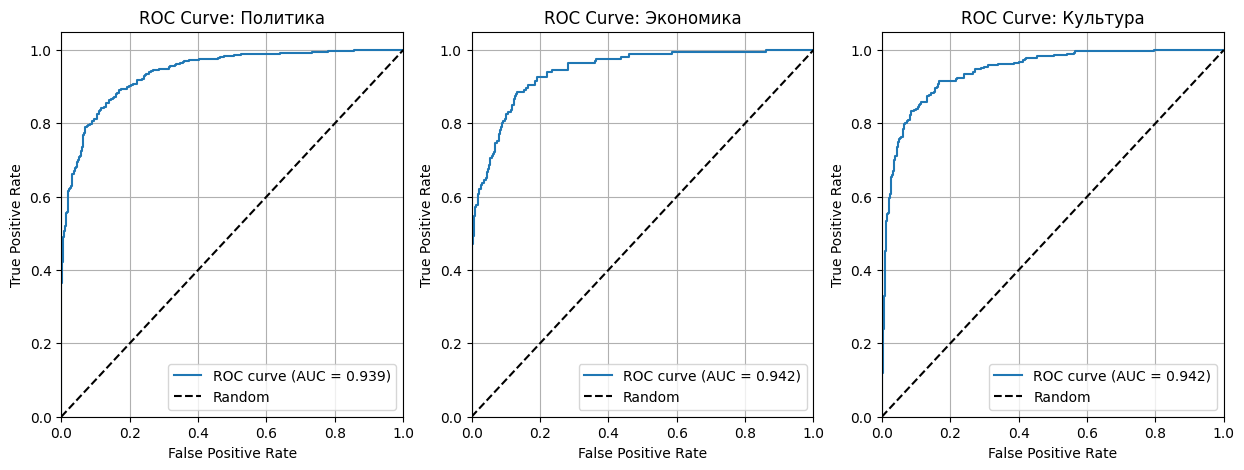

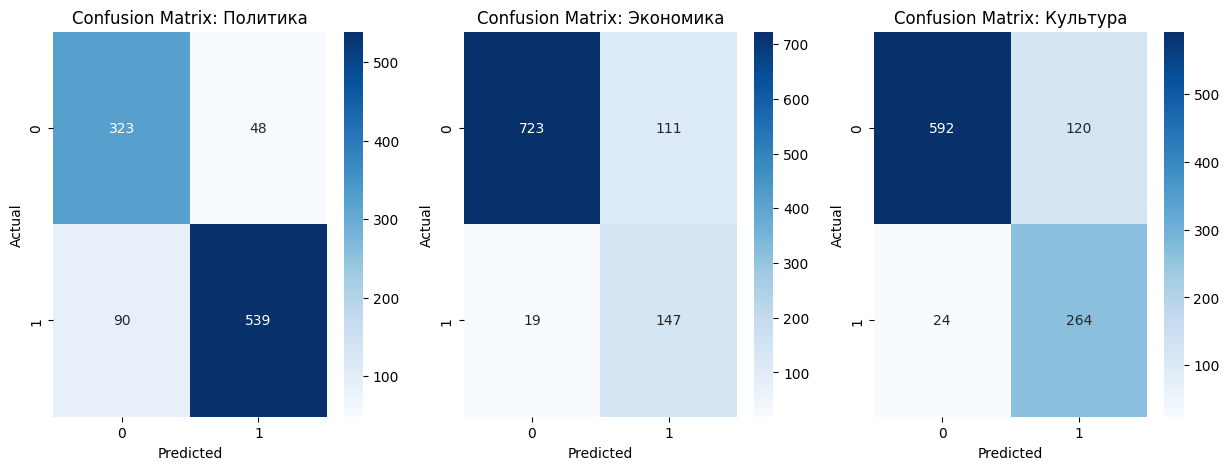

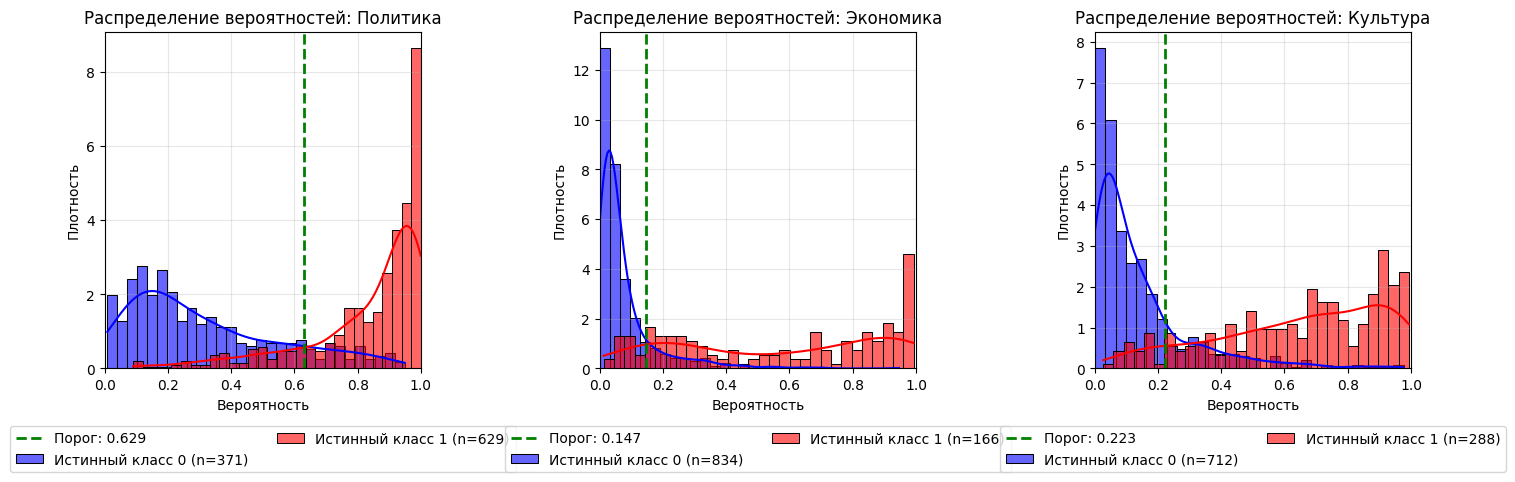


Сводная таблица метрик:
   category  accuracy  precision  recall  f1_score  auc_roc
0  politics     0.862     0.9182  0.8569    0.8865   0.9392
1   economy     0.870     0.5698  0.8855    0.6934   0.9423
2   culture     0.856     0.6875  0.9167    0.7857   0.9422


In [14]:
print("Оценка модели...")
metrics_df = evaluate_heads_with_plots_and_roc(model, X_test, y_test, tokenizer)
print("\n" + "="*50)
print("Сводная таблица метрик:")
print(metrics_df[['category', 'accuracy', 'precision', 'recall', 'f1_score', 'auc_roc']].round(4))

## 9. Деплой и мониторинг, A/B - 2 балла

Опишите, как вы будете выкатывать в модель в прод:
- как будет выглядеть пайплайн от момента, когда вам пришел текст и заголовок новости, до передачи вердиктов по категориям новости.
- как вы распределите железо для инференса: будет использоваться GPU или CPU (или какая-то комбинация), и как вы это обоснуете.
- как бы вы проводили A/B тест с учетом вашего ML и бизнес-целей? Что бы замеряли? Как бы делили на группы? Как измеряли бы значимость изменений?
- как бы вы настраивали мониторинг? Что бы отслеживали? Для чего бы вы это делали?

In [15]:
"""Для BERT части можно использовать GPU, для классификаторов - CPU. Доступно больше GPU - модель можно инференсить полностью на GPU

Для A/B теста выделил бы контрольную группу пользователей, для которых новости по рубрикам распределяла бы модель, и оценивал количество переходов 
по статьям, а так же количество кликов по рекламным блокам в статьях.

Так же выделил бы контрольную группу редакторов, которые должны были бы корректровать неверное распределения статей по рубрикам 
и оценивал количество ручных вмешательств

Мониторить можно параметры удержанимя внимания (дочитал ли пользователь статью до конца), CTR по рекламным блокам и количество ручных правок рубрик
"""


# ---- Ваш код здесь ----
print("вот так будет выглядеть деплой, вот это на GPU или CPU, а вот это будем мониторить")
# ---- Конец кода ----

вот так будет выглядеть деплой, вот это на GPU или CPU, а вот это будем мониторить


## 10. Итерации улучшения - 3 балла

Проанализируйте внимательно ваше решение, какие в нем есть проблемы и что можно улучшить. Придумайте (сами) максимально полный список того, что можно в модели сделать по-другому и улучшить, чтобы повысить качество модели.

**При желании** (это не повлияет на оценку), выберите одно из таких улучшений, внедрите, после чего выведите в одной ячейке метрики на тесте вашего прошлого и нового решений -- удалось ли улучшить результат?

In [16]:

# ---- Ваш код здесь ----
print("""можно применить DDP для распределенного train, желательно привлечь асессоров для доразметки выборки, 
имеет смысл для каждого класса сделать свою голову модели""")
# ---- Конец кода ----

можно применить DDP для распределенного train, желательно привлечь асессоров для доразметки выборки, 
имеет смысл для каждого класса сделать свою голову модели


## 11. Расширение категорий (10 баллов)

Как это часто бывает, к вам пришел бизнес и сказал: "мы передумали".

Всё тщательно обсудив на встрече, главный продакт-менеджер заявил, что новостное агентство нуждается в другом наборе категорий, а именно: нужно выделить новые категории, "технологии" и "спорт", а три старые в целом могут оставаться на месте (правда никто не знает, надолго ли).

Итого, **новый список:** `["политика","экономика","технологии","спорт","культура"]`

Реализуйте это изменение и выведите новые метрики по всем категориям (старым и новым), но перед этим посмотрите на архитектуру своего решения и ответьте на вопрос -- насколько легко и удобно будет а) добавлять новые категории в вашем ML б) перекатывать сервис?

In [17]:
"""Для изменения нужна доразметка, соответственно изменение промпта, функции разметки и класса для Structured Output.
Для использования предобученных весов реализуем функцию load_model_with_new_head, это позволит не учить модель с нуля, а использовать уже
имеющиеся веса
Для реализации новой модели отнаследуемся от старой и добавим необходимый функционал (дополнительную голову)"""

'Для изменения нужна доразметка, соответственно изменение промпта, функции разметки и класса для Structured Output.\nДля использования предобученных весов реализуем функцию load_model_with_new_head, это позволит не учить модель с нуля, а использовать уже\nимеющиеся веса\nДля реализации новой модели отнаследуемся от старой и добавим необходимый функционал (дополнительную голову)'

In [64]:
from typing import List, Union, Literal, Annotated
from annotated_types import MaxLen, Le, MinLen
from pydantic import BaseModel, Field
import json
from openai import OpenAI
#ollama endpoint
class LabelsAdd(BaseModel):
    economy: bool = Field('Является новостью экономики')
    culture: bool = Field('Является новостью культуры')
    politics: bool = Field('Является новостью политики')
    sport: bool = Field('Является новостью спорта')
    tech: bool = Field('Является новостью технологий')
    generation: str = Field('ответ в сыром виде')
client = OpenAI(base_url='http://192.168.1.3:11434/v1', api_key='ollama', )
prompt = """
    Ты помошник редактора новостей который занимается категорированием новостей.
    Твоя задача соотнести каждую входящую статью с определенными рубриками:
    -экономика
    -культура
    -политика
    -технологии
    -спорт
    рубрика культура обычно не пересекается с рубриками политики и экономики
"""


In [75]:
def process_row_ext(source: str, title: str, text: str, publication_date: str):
    log = [
                    {"role": "system", "content": prompt},
                    {"role": "user", "content": title + ' ' +  text},
            ]
    completion = client.beta.chat.completions.parse(
                         model="OxW/Saiga_YandexGPT_8B:Q8_0",
                         response_format=LabelsAdd,
                         messages=log,
                         max_completion_tokens=1000,
                         #reasoning_effort='low',
                         temperature=0.15
                     )
    r =[]
    for c in completion.choices:
        data = json.loads(c.message.content)
        d = {
            'source':  source,
            'title': title, 
            'text': text,
            'publication_date': publication_date,
            'politics': data['politics'],
            'economy': data['economy'],
            'culture': data['culture'],
            'tech': data['tech'],
            'sport': data['sport'],
            'generation': c.message
        }
        r.append(d)
    
    return r
result = pd.DataFrame()
for idx, row in tqdm(df[:5000].iterrows()):
    #print(process_row(row['source'], row['title'], row['text'][:1500], row['publication_date']))
    df_new = pd.DataFrame(process_row_ext(row['source'], row['title'], row['text'][:3000], row['publication_date']))
    result = pd.concat([result, df_new], ignore_index=True)
result.to_csv('prepared_ext.csv', sep=';', index=False)

#в теории можно распараллелить

5000it [2:16:57,  1.64s/it]


In [18]:
result = pd.read_csv('prepared_ext.csv', sep=';')
# формируем новые наборы, со стратификацией
X = result.drop(columns=['politics', 'economy', 'culture', 'tech', 'sport'])
y = result[['politics', 'economy', 'culture', 'tech', 'sport']]

msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

# ---- Ваш код здесь ----
print("EDA и разделение на трейн-тест")
# ---- Конец кода ----
for train_index, test_index in msss.split(X, y):
    X_train = X.iloc[train_index].reset_index(drop=True)
    X_test = X.iloc[test_index].reset_index(drop=True)
    y_train = y.iloc[train_index].reset_index(drop=True)
    y_test = y.iloc[test_index].reset_index(drop=True)


EDA и разделение на трейн-тест


In [19]:
class TripleHeadBERT(DualHeadBERT):
    def __init__(self, model_name, num_labels=3, added_labels=2):
        super().__init__(model_name, num_labels)
        self.head3 = nn.Linear(self.hidden_size, added_labels)
        self.head4 = nn.Linear(self.hidden_size, added_labels)
        for param in self.head1.parameters():
            param.requires_grad = False
        for param in self.head2.parameters():
            param.requires_grad = False
    def forward(self, input_ids, attention_mask=None):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_token = outputs.last_hidden_state[:, 0, :]
        logits1 = self.head1(cls_token)
        logits2 = self.head2(cls_token)
        logits3 = self.head3(cls_token)
        logits4 = self.head4(cls_token)
        logits = torch.cat([torch.sigmoid((logits1 + logits2) / 2), torch.sigmoid((logits3 + logits4) /2)], dim=1)
        return logits

In [20]:
def load_model_with_new_head(model_path, num_labels=3, added_labels=2):
    model = TripleHeadBERT("DeepPavlov/rubert-base-cased", num_labels=num_labels, added_labels=added_labels)
    old_state_dict = torch.load(model_path, map_location='cpu', weights_only=True)
    new_state_dict = model.state_dict()
    for key in ['head1.weight', 'head1.bias', 'head2.weight', 'head2.bias']:
        if key in old_state_dict:
            new_state_dict[key] = old_state_dict[key]
    model.load_state_dict(new_state_dict)
    return model

In [21]:
model = load_model_with_new_head("dual_head_bert.pth", 3, 2)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [23]:
NUM_EPOCHS = 100
LR = 0.001
BATCH_SIZE = 64

train_ds = NewsDataset(X_train, y_train, tokenizer)
test_ds = NewsDataset(X_test, y_test, tokenizer)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    pin_memory=True,
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    pin_memory=True,
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model.to(device)
criterion = nn.BCELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)


for epoch in tqdm(range(NUM_EPOCHS)):
    model.train()
    train_loss = 0.0
    train_preds = []
    train_labels = []
    
    for batch in train_loader:
        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].to(device)
        
        optimizer.zero_grad()
        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels.float())
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        
 
        preds = (logits > 0.5).float()
        train_preds.append(preds.cpu())
        train_labels.append(labels.cpu())
    
    model.eval()
    val_loss = 0.0
    val_preds = []
    val_labels = []
    
    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch[0].to(device)
            attention_mask = batch[1].to(device)
            labels = batch[2].to(device)
            
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels.float())
            val_loss += loss.item()
            

            preds = (logits > 0.5).float()
            val_preds.append(preds.cpu())
            val_labels.append(labels.cpu())
    
 
    train_preds_all = torch.cat(train_preds)
    train_labels_all = torch.cat(train_labels)
    val_preds_all = torch.cat(val_preds)
    val_labels_all = torch.cat(val_labels)
    
    train_f1_micro = f1_score(train_labels_all, train_preds_all, average='micro')
    train_f1_macro = f1_score(train_labels_all, train_preds_all, average='macro')
    val_f1_micro = f1_score(val_labels_all, val_preds_all, average='micro')
    val_f1_macro = f1_score(val_labels_all, val_preds_all, average='macro')
    
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}")
    print(f"  Train Loss: {train_loss/len(train_loader):.4f}, F1 Micro: {train_f1_micro:.4f}, F1 Macro: {train_f1_macro:.4f}")
    print(f"  Val Loss:   {val_loss/len(test_loader):.4f}, F1 Micro: {val_f1_micro:.4f}, F1 Macro: {val_f1_macro:.4f}")
    print(f"  Device: {device}")

    scheduler.step(val_loss)

# Сохранение модели
torch.save(model.state_dict(), "triple_head_bert.pth")
print("Модель сохранена в triple_head_bert.pth")

  1%|▊                                                                                 | 1/100 [00:16<27:05, 16.42s/it]

Epoch 1/100
  Train Loss: 0.2080, F1 Micro: 0.8361, F1 Macro: 0.7584
  Val Loss:   0.2073, F1 Micro: 0.8265, F1 Macro: 0.7350
  Device: cuda


  2%|█▋                                                                                | 2/100 [00:33<27:10, 16.64s/it]

Epoch 2/100
  Train Loss: 0.2069, F1 Micro: 0.8336, F1 Macro: 0.7644
  Val Loss:   0.2061, F1 Micro: 0.8270, F1 Macro: 0.7389
  Device: cuda


  3%|██▍                                                                               | 3/100 [00:49<26:51, 16.62s/it]

...

Epoch 58/100
  Train Loss: 0.1955, F1 Micro: 0.8418, F1 Macro: 0.8003
  Val Loss:   0.1939, F1 Micro: 0.8358, F1 Macro: 0.7832
  Device: cuda


 59%|███████████████████████████████████████████████▊                                 | 59/100 [16:43<11:47, 17.26s/it]

Epoch 59/100
  Train Loss: 0.1934, F1 Micro: 0.8452, F1 Macro: 0.8104
  Val Loss:   0.1939, F1 Micro: 0.8367, F1 Macro: 0.7871
  Device: cuda


 59%|███████████████████████████████████████████████▊                                 | 59/100 [16:56<11:46, 17.22s/it]


KeyboardInterrupt: 

In [24]:
torch.save(model.state_dict(), "triple_head_bert.pth")
print("Модель сохранена в triple_head_bert.pth")

Модель сохранена в triple_head_bert.pth


In [25]:
model = TripleHeadBERT("DeepPavlov/rubert-base-cased", num_labels=3, added_labels=2)
model.load_state_dict(torch.load("triple_head_bert.pth", map_location=device, weights_only=True))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<All keys matched successfully>

Оценка модели...


C:\Users\Vampire\AppData\Local\Temp\ipykernel_15016\2037580155.py:166: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


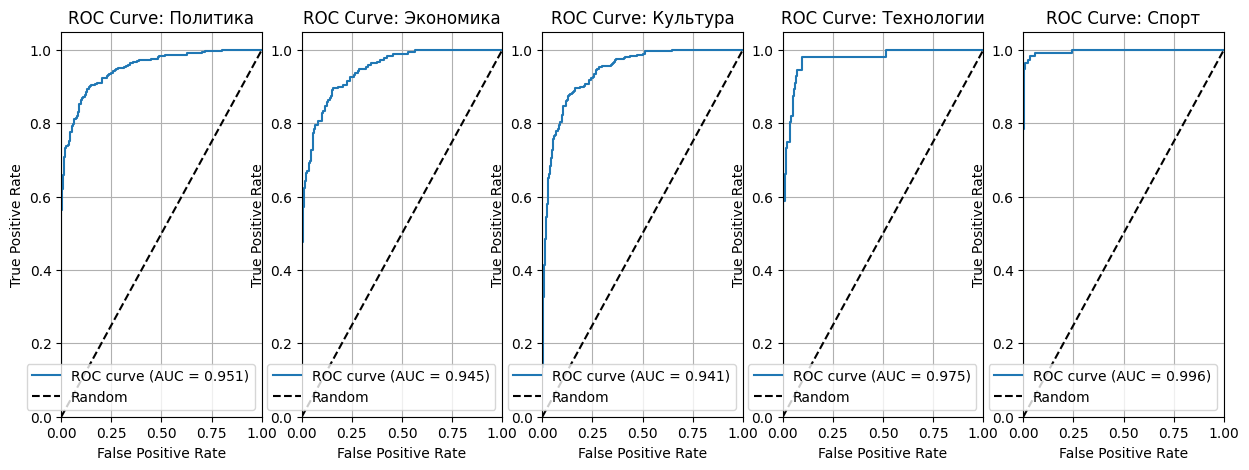

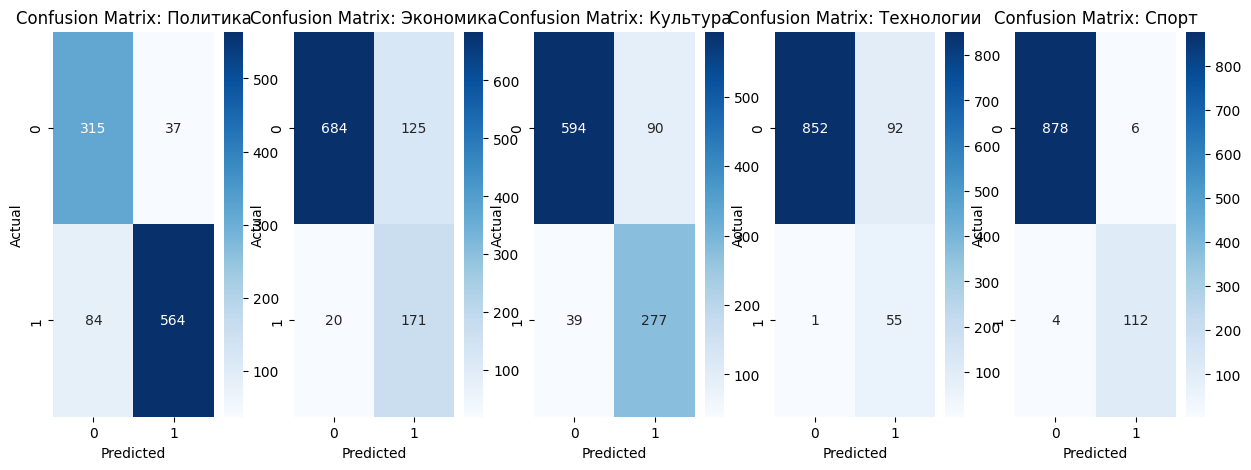

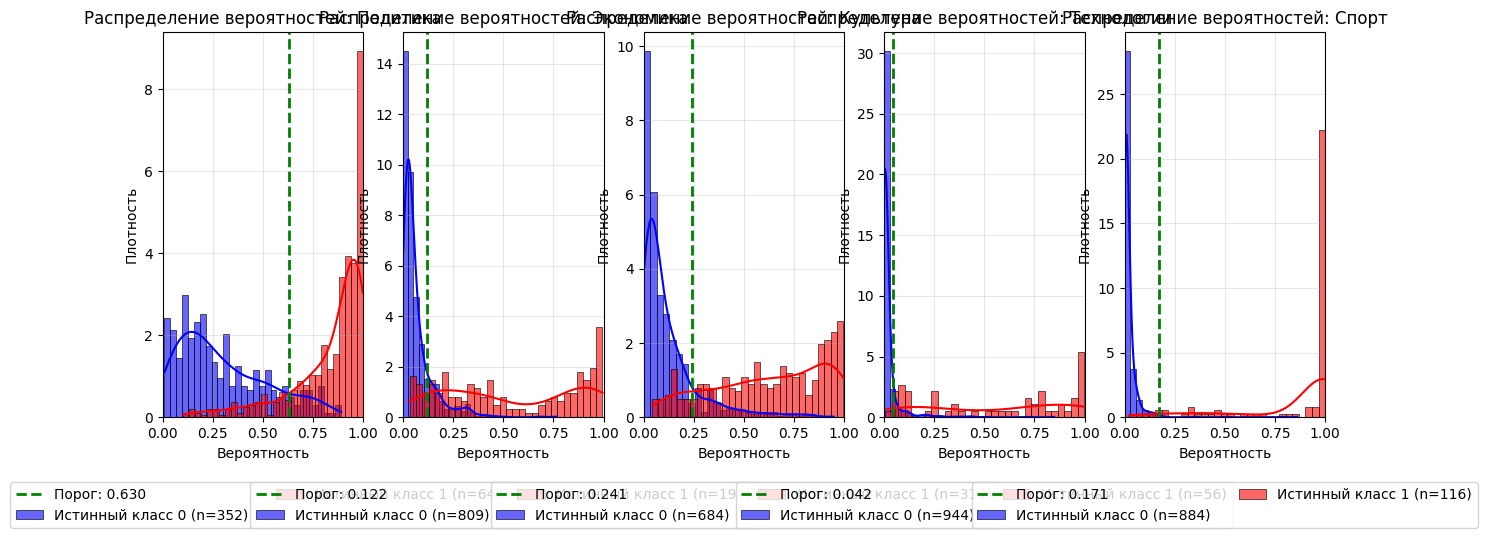


Сводная таблица метрик:
   category  accuracy  precision  recall  f1_score  auc_roc
0  politics     0.879     0.9384  0.8704    0.9031   0.9510
1   economy     0.855     0.5777  0.8953    0.7023   0.9452
2   culture     0.871     0.7548  0.8766    0.8111   0.9408
3      tech     0.907     0.3741  0.9821    0.5419   0.9749
4     sport     0.990     0.9492  0.9655    0.9573   0.9963


In [26]:
print("Оценка модели...")
metrics_df = evaluate_heads_with_plots_and_roc(model, X_test, y_test, tokenizer, {
            'politics': 'Политика',
            'economy': 'Экономика', 
            'culture': 'Культура',
            'tech': 'Технологии',
            'sport': 'Спорт'
        })
print("\n" + "="*50)
print("Сводная таблица метрик:")
print(metrics_df[['category', 'accuracy', 'precision', 'recall', 'f1_score', 'auc_roc']].round(4))